# Vision Transformer Training

Training of the Vision Transformer from [An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale](https://arxiv.org/abs/2010.11929) (Dosovitskiy et al., 2020) on the [UC Merced Land Use dataset](http://weegee.vision.ucmerced.edu/datasets/landuse.html).

In this notebook I split the processed images into training and validation sets, build the ViT-Base/16 model from `src/vit/model.py`, and train it from scratch with the training loop from `src/vit/train.py`.

**Contents**
1. Setup
2. Data
3. Model
4. Training
5. Loss curves
6. Evaluation
7. Example predictions
8. Conclusion

## 1. Setup

In [1]:
import os
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from torchvision import transforms

from vit.dataset import create_dataloaders
from vit.model import ViT
from vit.train import train

In [2]:
DATA_PATH = Path("../data/")
PROCESSED_IMAGES_PATH = DATA_PATH / "processed"
TRAIN_PATH = DATA_PATH / "train"
VAL_PATH = DATA_PATH / "val"

IMAGE_SIZE = 256  # H = W
BATCH_SIZE = 32
EPOCHS = 10

In [3]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

device

'cuda'

In [4]:
def set_seed(seed: int = 42):
    """Seeds PyTorch's CPU and CUDA random number generators for reproducible runs.

    Args:
        seed: Seed value passed to the generators.
    """
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

## 2. Data

The processed dataset from the data exploration notebook keeps one folder per land-use class, with every image at $256 \times 256$.

In [5]:
def extract_all_dataset_image_paths(dataset_path: str):
    """Lists all image paths in a dataset.

    Args:
        dataset_path: Path to the dataset.

    Returns:
        A list with the path of every image in the dataset.
    """
    all_samples = []
    for class_name in os.listdir(dataset_path):
        class_path = os.path.join(dataset_path, class_name)
        if os.path.isdir(class_path):
            for sample_name in os.listdir(class_path):
                sample_path = os.path.join(class_path, sample_name)
                all_samples.append(sample_path)
    return all_samples

In [6]:
image_paths = extract_all_dataset_image_paths(PROCESSED_IMAGES_PATH)

print(f"Total number of images in processed dataset: {len(image_paths)}")

Total number of images in processed dataset: 2056


### 2.1 Train and validation split

Dropping the off-size images left the classes slightly unbalanced, so the 80/20 split is stratified by class to keep the class ratios equal in both sets.

In [7]:
# Parent folder name is the class label, used to keep class ratios equal across splits
labels = [os.path.basename(os.path.dirname(path)) for path in image_paths]

train_paths, val_paths = train_test_split(
    image_paths, test_size=0.2, random_state=42, stratify=labels
)

print(f"Number of training images: {len(train_paths)}")
print(f"Number of validation images: {len(val_paths)}")

Number of training images: 1644
Number of validation images: 412


In [8]:
def copy_images(paths, destination_dir):
    """Copies images into per-class subfolders of a destination directory.

    Each image is placed under destination_dir/<class_name>/, where class_name
    is the name of the image's parent folder. This matches the layout expected
    by torchvision.datasets.ImageFolder.

    Args:
        paths: List of image paths to copy.
        destination_dir: Directory where images will be copied.
    """
    for path in paths:
        class_name = os.path.basename(os.path.dirname(path))
        class_dir = os.path.join(destination_dir, class_name)
        os.makedirs(class_dir, exist_ok=True)
        shutil.copy(path, class_dir)

In [9]:
copy_images(train_paths, TRAIN_PATH)
copy_images(val_paths, VAL_PATH)

### 2.2 DataLoaders

The images already have the size the model expects, and `ToTensor` turns them into $(C, H, W)$ tensors with values in $[0, 1]$.

In [10]:
manual_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])
print(f"Manually created transforms: {manual_transforms}")

Manually created transforms: Compose(
    Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


In [11]:
train_dataloader, val_dataloader, class_names = create_dataloaders(
    train_dir=TRAIN_PATH,
    test_dir=VAL_PATH,
    transform=manual_transforms,
    batch_size=BATCH_SIZE,
)

train_dataloader, val_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x7e36a12dc1a0>,
 ['agricultural',
  'airplane',
  'baseballdiamond',
  'beach',
  'buildings',
  'chaparral',
  'denseresidential',
  'forest',
  'freeway',
  'golfcourse',
  'harbor',
  'intersection',
  'mediumresidential',
  'mobilehomepark',
  'overpass',
  'parkinglot',
  'river',
  'runway',
  'sparseresidential',
  'storagetanks',
  'tenniscourt'])

In [12]:
image_batch, label_batch = next(iter(train_dataloader))

In [13]:
image, label = image_batch[0], label_batch[0]

image.shape, label, class_names[label]

(torch.Size([3, 256, 256]), tensor(8), 'freeway')

(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

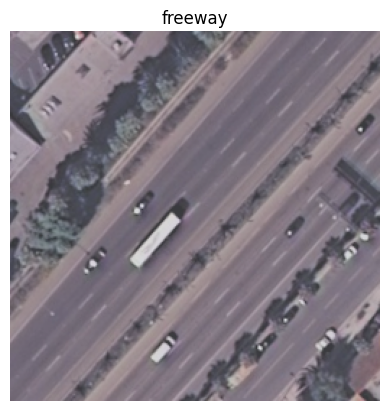

In [14]:
plt.imshow(image.permute(1, 2, 0))
plt.title(class_names[label])
plt.axis(False)

## 3. Model

The model uses the ViT-Base sizes from Table 1 ($L = 12$, $D = 768$, MLP size $3072$, $h = 12$) with $P = 16$, and dropout $0.1$ (Table 3).

In [15]:
set_seed()

model = ViT(
    image_size=IMAGE_SIZE,
    patch_size=16,
    num_classes=len(class_names),
    embedding_dim=768,
    num_transformer_layers=12,
    num_heads=12,
    mlp_dim=3072,
    mlp_dropout=0.1,
    embedding_dropout=0.1,
)

## 4. Training

Appendix B.1 trains with Adam ($\beta_1 = 0.9$, $\beta_2 = 0.999$), a batch size of 4096 and a linear learning rate warmup followed by a decay. For ViT-B/16 on ImageNet, Table 3 uses a base learning rate of $3 \cdot 10^{-3}$, weight decay $0.3$, cosine decay and a warmup of 10k steps. Cross-entropy is the classification loss. Fine-tuning in the paper uses SGD with momentum and a batch size of 512, but this model is trained from scratch.

The scheduler is stepped after every batch, so the warmup and decay lengths are measured in optimizer steps rather than epochs. The dataset is far smaller than ImageNet, so the warmup is shortened to one epoch.

In [16]:
TOTAL_STEPS = EPOCHS * len(train_dataloader)
WARMUP_STEPS = len(train_dataloader)

optimizer = torch.optim.AdamW(params=model.parameters(), lr=3e-3, weight_decay=0.3, betas=(0.9, 0.999))
loss_fn = nn.CrossEntropyLoss()

warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer=optimizer,
    start_factor=1e-3,
    end_factor=1.0,
    total_iters=WARMUP_STEPS
)
decay_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer=optimizer,
    T_max=TOTAL_STEPS - WARMUP_STEPS
)
lr_scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer=optimizer,
    schedulers=[warmup_scheduler, decay_scheduler],
    milestones=[WARMUP_STEPS]
)

model = model.to(device)

results = train(
    model=model,
    train_dataloader=train_dataloader,
    test_dataloader=val_dataloader,
    optimizer=optimizer,
    loss_fn=loss_fn,
    epochs=EPOCHS,
    device=device,
    lr_scheduler=lr_scheduler,
)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 3.3446 | train_acc: 0.0521 | test_loss: 3.3522 | test_acc: 0.0481
Epoch: 2 | train_loss: 3.3164 | train_acc: 0.0551 | test_loss: 3.1984 | test_acc: 0.0457
Epoch: 3 | train_loss: 3.1720 | train_acc: 0.0503 | test_loss: 3.1766 | test_acc: 0.0549
Epoch: 4 | train_loss: 3.1351 | train_acc: 0.0433 | test_loss: 3.1120 | test_acc: 0.0481
Epoch: 5 | train_loss: 3.1418 | train_acc: 0.0495 | test_loss: 3.0759 | test_acc: 0.0508
Epoch: 6 | train_loss: 3.0991 | train_acc: 0.0481 | test_loss: 3.0640 | test_acc: 0.0481
Epoch: 7 | train_loss: 3.0702 | train_acc: 0.0403 | test_loss: 3.0513 | test_acc: 0.0913
Epoch: 8 | train_loss: 3.0511 | train_acc: 0.0609 | test_loss: 3.0144 | test_acc: 0.0687
Epoch: 9 | train_loss: 2.9934 | train_acc: 0.0773 | test_loss: 2.9262 | test_acc: 0.1010
Epoch: 10 | train_loss: 2.8882 | train_acc: 0.1054 | test_loss: 2.9090 | test_acc: 0.1130


## 5. Loss curves

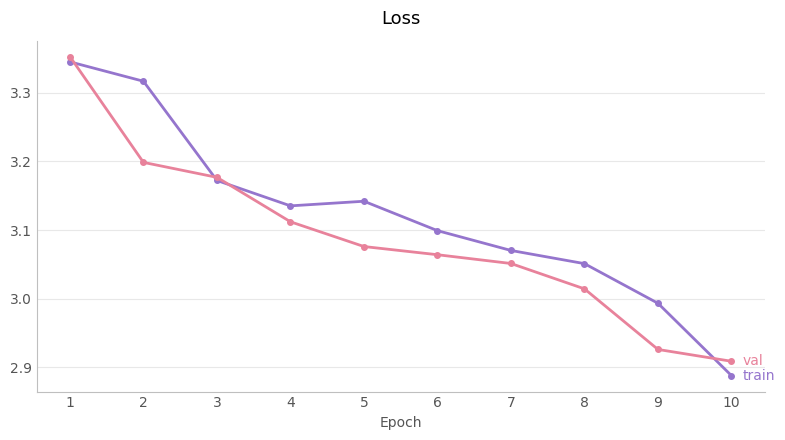

In [17]:
# Palette taken from the README GIFs (class token purple, patch embedding pink, light gray guides)
TRAIN_COLOR = "#9575cd"
VAL_COLOR = "#e8829b"
GUIDE_COLOR = "#bfbfbf"

epochs_range = range(1, len(results["train_loss"]) + 1)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor="white")
for key, label, color in [("train_loss", "train", TRAIN_COLOR), ("test_loss", "val", VAL_COLOR)]:
    ax.plot(epochs_range, results[key], color=color, linewidth=2, marker="o", markersize=4)
    # Label each curve at its last point instead of a legend box to keep the plot uncluttered
    ax.annotate(label, xy=(epochs_range[-1], results[key][-1]), xytext=(8, 0), textcoords="offset points", va="center", color=color, fontsize=10)

ax.set_title("Loss", fontsize=13, pad=12)
ax.set_xlabel("Epoch", color="#555555")
ax.set_xticks(list(epochs_range))
ax.grid(axis="y", color="#e8e8e8", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(GUIDE_COLOR)
ax.tick_params(colors="#555555", length=0)
plt.tight_layout()
plt.show()

## 6. Evaluation

The paper reports top-1 accuracy, so that is the main metric here. With 21 classes, a model that guesses at random gets $1/21 \approx 4.8\%$, which is the baseline to compare against.

Two more metrics help read a weak model:
- **Top-5 accuracy** checks whether the true class is among the five most likely ones, so it shows whether the model has learned something even when its first guess is wrong.
- **Macro one-vs-rest ROC AUC** scores how well the predicted probabilities rank each class above the others, averaged over classes. It ignores the argmax entirely, so it stays informative when accuracy is low. Random guessing gives $0.5$.

In [18]:
from sklearn.metrics import roc_auc_score

model.eval()
all_probs, all_labels = [], []
with torch.inference_mode():
    for X, y in val_dataloader:
        logits = model(X.to(device))
        all_probs.append(torch.softmax(logits, dim=1).cpu())
        all_labels.append(y)

# The validation DataLoader is not shuffled, so row i matches val_dataloader.dataset[i]
all_probs = torch.cat(all_probs)
all_labels = torch.cat(all_labels)
all_preds = all_probs.argmax(dim=1)

num_classes = len(class_names)
top1_accuracy = (all_preds == all_labels).float().mean().item()
top5_accuracy = (all_probs.topk(5, dim=1).indices == all_labels.unsqueeze(1)).any(dim=1).float().mean().item()
roc_auc = roc_auc_score(all_labels.numpy(), all_probs.numpy(), multi_class="ovr", average="macro")

print(f"Top-1 accuracy: {top1_accuracy:.2%}  (chance {1 / num_classes:.2%})")
print(f"Top-5 accuracy: {top5_accuracy:.2%}  (chance {5 / num_classes:.2%})")
print(f"Macro ROC AUC:  {roc_auc:.3f}   (chance 0.500)")

Top-1 accuracy: 11.41%  (chance 4.76%)
Top-5 accuracy: 41.02%  (chance 23.81%)
Macro ROC AUC:  0.685   (chance 0.500)


## 7. Example predictions

Eight random validation images, with the predicted class, its probability and the true class. The validation set is ordered by class, so the images are sampled instead of taking the first batch, which would all be the same class.

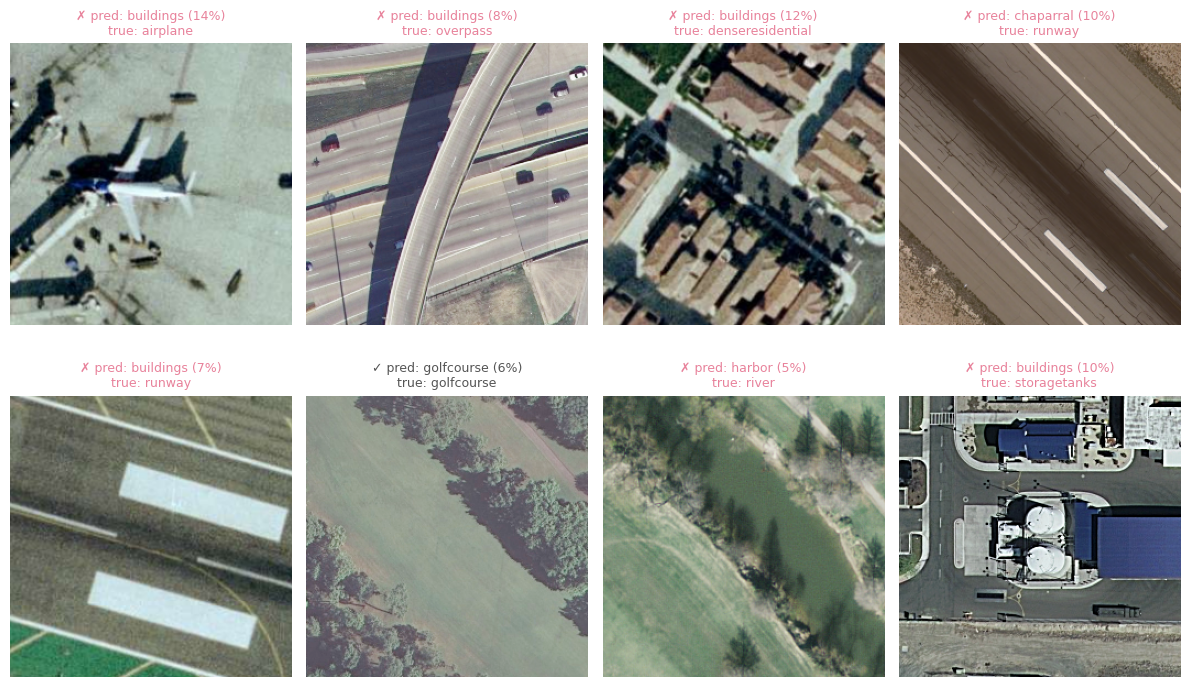

In [19]:
CORRECT_COLOR = "#555555"
WRONG_COLOR = VAL_COLOR

# Separate generator so the sample is fixed without touching the global seed used for training
generator = torch.Generator().manual_seed(42)
sample_indices = torch.randperm(len(all_labels), generator=generator)[:8].tolist()

fig, axes = plt.subplots(2, 4, figsize=(12, 7.5), facecolor="white")
for ax, idx in zip(axes.flat, sample_indices):
    image, label = val_dataloader.dataset[idx]
    pred = all_preds[idx].item()
    correct = pred == label
    ax.imshow(image.permute(1, 2, 0))
    # Mark correctness with a symbol as well as color, so it reads without relying on color alone
    ax.set_title(
        f"{'✓' if correct else '✗'} pred: {class_names[pred]} ({all_probs[idx, pred]:.0%})\ntrue: {class_names[label]}",
        color=CORRECT_COLOR if correct else WRONG_COLOR,
        fontsize=9,
    )
    ax.axis(False)
plt.tight_layout()
plt.show()

## 8. Conclusion

Compare the metrics in section 6 with the chance levels: anything above them means the model learned real signal, but the accuracy is far below what the paper reports. That is expected for this setup, and the gap comes from the training setup rather than the architecture:

- **The training is very short.** 10 epochs over 1644 images at batch size 32 is about 520 optimizer steps. In the paper (Table 3), ViT-B/16 trains for 300 epochs on ImageNet at batch size 4096, roughly 94k steps, each on 128 times more images.
- **The dataset is tiny.** The paper pre-trains on ImageNet (1.3M images), ImageNet-21k (14M) and JFT-300M (303M), against about 1.6k training images here. Section 4.2 and Figure 3 show that ViT only beats ResNets once the pre-training set is large, and that ViT-B trained on ImageNet alone already falls behind.
- **ViT has little built-in prior about images.** Section 3.1 explains that, unlike a CNN, only the MLP layers are local and translation equivariant, while self-attention is global, so the model has to learn spatial structure from data. With little data, that is what limits it.
- **The model is too large for the data.** ViT-Base has about 86M parameters for 1.6k images, so it can memorize the training set, which shows as a gap between the train and validation curves in section 5.
- **The paper's best results come from transfer.** Its strong numbers on small datasets come from pre-training on a large dataset and then fine-tuning, not from training from scratch on the target data.

The natural next step, following the paper, is to load pre-trained ViT-B/16 weights and fine-tune on UC Merced.